In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Вспомним, что было

**Вспомним, что такое точечная оценка**

**Вспомним асимптотические свойства оценок**

 1. **Свойство состоятельности**

**Вспомним свойства оценок при фиксированном размере выборки**

Проговорим, что такое:

 1. **Свойство несмещённости**
 2. **Среднеквадратичная ошибка оценки**
 3. **Функция вклада**
 4. **Информация Фишера**
 5. **Свойство эффективности оценки**

# Задача 1. Сравнение двух оценок

Пусть $X_1,\ldots,X_{10}$ независимы и одинаково распределены, причём

$$
\mathbb{E}[X_i] = \theta,
\qquad
\operatorname{Var}(X_i) = 4.
$$

Рассмотрим две оценки параметра $\theta$:

$$
\widehat{\theta}_1 = \overline{X},
\qquad
\widehat{\theta}_2 = 0.8\overline{X} + 1.
$$

1. Найди смещение и дисперсию оценки $\widehat{\theta}_1$.

2. Найди смещение и дисперсию оценки $\widehat{\theta}_2$.

3. Вычисли $\operatorname{MSE}_{\theta}$ обеих оценок и определи значения $\theta$, при которых $\widehat{\theta}_2$ имеет меньшую MSE.

4. Объясни, почему смещённая оценка $\widehat{\theta}_2$ может оказаться лучше несмещённой оценки $\widehat{\theta}_1$.

5. Визуализируй полученный результат на графике.

**Решение**


## Пункт 1. Смещение и дисперсия первой оценки

Рассмотрим

$$
\widehat{\theta}_1=\overline{X}.
$$

Так как $\mathbb{E}[X_i]=\theta$, то

$$
\mathbb{E}[\overline{X}]
=
\frac{1}{10}\sum_{i=1}^{10}\mathbb{E}[X_i]
=
\theta.
$$

Поэтому смещение первой оценки равно

$$
\operatorname{Bias}_{\theta}(\widehat{\theta}_1)
=
\mathbb{E}[\widehat{\theta}_1]-\theta
=
0.
$$

Следовательно, $\widehat{\theta}_1$ является несмещённой оценкой.

Так как наблюдения независимы,

$$
\operatorname{Var}(\overline{X})
=
\frac{\operatorname{Var}(X_i)}{10}
=
\frac{4}{10}
=
0.4.
$$

Таким образом,

$$
\boxed{
\operatorname{Bias}_{\theta}(\widehat{\theta}_1)=0,
\qquad
\operatorname{Var}(\widehat{\theta}_1)=0.4
}.
$$

## Пункт 2. Смещение и дисперсия второй оценки

Рассмотрим

$$
\widehat{\theta}_2=0.8\overline{X}+1.
$$

По линейности математического ожидания

$$
\mathbb{E}[\widehat{\theta}_2]
=
0.8\mathbb{E}[\overline{X}]+1
=
0.8\theta+1.
$$

Следовательно,

$$
\operatorname{Bias}_{\theta}(\widehat{\theta}_2)
=
\mathbb{E}[\widehat{\theta}_2]-\theta
=
1-0.2\theta.
$$

При добавлении константы дисперсия не меняется, поэтому

$$
\operatorname{Var}(\widehat{\theta}_2)
=
0.8^2\operatorname{Var}(\overline{X})
=
0.64\cdot0.4
=
0.256.
$$

Таким образом,

$$
\boxed{
\operatorname{Bias}_{\theta}(\widehat{\theta}_2)=1-0.2\theta,
\qquad
\operatorname{Var}(\widehat{\theta}_2)=0.256
}.
$$

## Пункт 3. Сравнение оценок по MSE

Для любой оценки

$$
\operatorname{MSE}_{\theta}(\widehat{\theta})
=
\operatorname{Var}(\widehat{\theta})
+
\operatorname{Bias}_{\theta}(\widehat{\theta})^2.
$$

Для первой оценки смещение равно нулю, поэтому

$$
\operatorname{MSE}_{\theta}(\widehat{\theta}_1)
=
0.4.
$$

Для второй оценки

$$
\operatorname{MSE}_{\theta}(\widehat{\theta}_2)
=
0.256+(1-0.2\theta)^2.
$$

Вторая оценка имеет меньшую MSE, если

$$
0.256+(1-0.2\theta)^2<0.4.
$$

Отсюда

$$
(1-0.2\theta)^2<0.144,
$$

или

$$
|1-0.2\theta|<\sqrt{0.144}.
$$

Так как $\sqrt{0.144}\approx0.3795$, получаем

$$
-0.3795<1-0.2\theta<0.3795.
$$

Решая двойное неравенство относительно $\theta$, получаем

$$
\boxed{
3.103<\theta<6.897
}.
$$

Таким образом, при $3.103<\theta<6.897$ вторая оценка имеет меньшую MSE.

## Пункт 4. Почему смещённая оценка может быть лучше?

У первой оценки нет смещения, но её дисперсия равна $0.4$.

У второй оценки есть смещение $1-0.2\theta$, зато её дисперсия меньше:

$$
0.256<0.4.
$$

MSE учитывает одновременно и разброс оценки, и её смещение:

$$
\operatorname{MSE}
=
\operatorname{Var}
+
\operatorname{Bias}^2.
$$

Поэтому небольшое смещение может быть выгодным, если оно позволяет достаточно сильно уменьшить дисперсию.

В этой задаче при $3.103<\theta<6.897$ уменьшение дисперсии компенсирует квадрат смещения, поэтому $\widehat{\theta}_2$ имеет меньшую MSE.

## Пункт 5. Визуализация

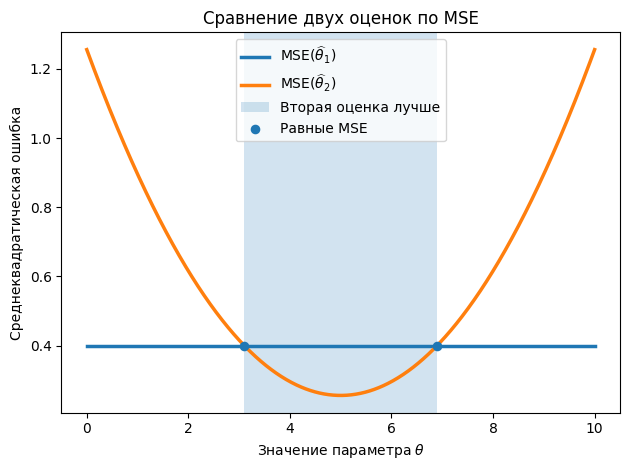

In [2]:
theta_grid = np.linspace(0, 10, 1001)

mse_first = np.full_like(theta_grid, 0.4)
mse_second = 0.256 + (1 - 0.2 * theta_grid) ** 2

radius = np.sqrt(0.4 - 0.256)
lower_bound = (1 - radius) / 0.2
upper_bound = (1 + radius) / 0.2

plt.plot(theta_grid, mse_first, linewidth=2.5, label=r"$\operatorname{MSE}(\widehat{\theta}_1)$")
plt.plot(theta_grid, mse_second, linewidth=2.5, label=r"$\operatorname{MSE}(\widehat{\theta}_2)$")
plt.axvspan(lower_bound, upper_bound, alpha=0.2, label="Вторая оценка лучше")

plt.scatter(
    [lower_bound, upper_bound],
    [0.4, 0.4],
    s=35,
    zorder=3,
    label="Равные MSE"
)

plt.xlabel(r"Значение параметра $\theta$")
plt.ylabel("Среднеквадратическая ошибка")
plt.title("Сравнение двух оценок по MSE")
plt.legend()
plt.tight_layout()
plt.show()

# Задача 2. Смещение и дисперсия выборочной доли

Пусть $X_1,\ldots,X_n$ - независимая выборка, где
$X_i\sim\operatorname{Bernoulli}(p)$ и истинное значение параметра равно $p=0.35$. Требуется исследовать оценку параметра $p$ - выборочную долю

$$
\widehat p_n=\frac1n\sum_{i=1}^n X_i
$$

для объёмов выборки $n\in\{20,100,500\}$.

До моделирования аналитически найди $\mathbb E[\widehat p_n]$, $\operatorname{Bias}(\widehat p_n)$ и $\operatorname{Var}(\widehat p_n)$.

Затем проведи воспроизводимую симуляцию: для каждого $n$ выполни одно и то же заранее заданное число $R=50\,000$ независимых повторов.

В каждом повторе должна генерироваться новая независимая выборка Бернулли того же размера $n$ и вычисляться новая оценка $\widehat p_n^{(r)}$. По полученным $R$ оценкам вычисли эмпирическое среднее

$$
\overline{\widehat p}_n=\frac1R\sum_{r=1}^R\widehat p_n^{(r)},
$$

эмпирическое смещение

$$
\widehat{\operatorname{Bias}}_R(\widehat p_n)
=\frac1R\sum_{r=1}^R\widehat p_n^{(r)}-p,
$$

и эмпирическую выборочную дисперсию

$$
\widehat{\operatorname{Var}}_R(\widehat p_n)
=\frac1{R-1}\sum_{r=1}^R
\left(\widehat p_n^{(r)}-\overline{\widehat p}_n\right)^2.
$$

Именно к дисперсии **оценок по независимым повторам** применяется `ddof=1`; это не дисперсия отдельных наблюдений Бернулли.

Составь итоговую таблицу, которая для каждого $n$ сопоставляет эмпирическое среднее, эмпирическое и теоретическое смещения, эмпирическую дисперсию с `ddof=1` и точную дисперсию $p(1-p)/n$.

Добавь абсолютное отклонение эмпирической дисперсии от теоретической и их отношение. Проверь, что дисперсия уменьшается примерно обратно пропорционально объёму выборки: при пятикратном росте $n$ она должна уменьшаться примерно в пять раз.

Объясни несмещённость оценки и почему небольшое ненулевое эмпирическое смещение при конечном $R$ не противоречит точному нулевому смещению.

**Решение**

**Математическое ожидание**

По линейности математического ожидания и поскольку $\mathbb E[X_i]=p$ для $X_i\sim\operatorname{Bernoulli}(p)$,

$$
\begin{aligned}
\mathbb E[\widehat p_n]=\mathbb E\!\left[\frac1n\sum_{i=1}^nX_i\right]=\frac1n\sum_{i=1}^n\mathbb E[X_i]=\frac1n\sum_{i=1}^n p
=\frac{np}{n}=p.
\end{aligned}
$$

**Смещение**

Подставим найденное математическое ожидание в определение смещения:

$$
\operatorname{Bias}(\widehat p_n)
=\mathbb E[\widehat p_n]-p=p-p=0.
$$

Следовательно, выборочная доля несмещённо оценивает $p$ при любом $n$.

**Дисперсия**

Для случайной величины Бернулли $\operatorname{Var}(X_i)=p(1-p)$. Кроме того, $\operatorname{Var}(aY)=a^2\operatorname{Var}(Y)$. Поэтому

$$
\operatorname{Var}(\widehat p_n)
=\operatorname{Var}\!\left(\frac1n\sum_{i=1}^nX_i\right)
=\frac1{n^2}\operatorname{Var}\!\left(\sum_{i=1}^nX_i\right).
$$

Тогда:

$$
\begin{aligned}
\operatorname{Var}(\widehat p_n)=\frac1{n^2}\sum_{i=1}^n\operatorname{Var}(X_i)=\frac1{n^2}\sum_{i=1}^n p(1-p)=\frac{np(1-p)}{n^2}
=\frac{p(1-p)}n.
\end{aligned}
$$



**Численные теоретические значения**

При $p=0.35$ имеем

$$
p(1-p)=0.35\cdot0.65=0.2275.
$$

Следовательно,

$$
\begin{array}{c|c|c}
n & \operatorname{Bias}(\widehat p_n) & \operatorname{Var}(\widehat p_n)\\ \hline
20  & 0 & 0.2275/20=0.011375\\
100 & 0 & 0.2275/100=0.002275\\
500 & 0 & 0.2275/500=0.000455
\end{array}
$$

При увеличении $n$ с $20$ до $100$ дисперсия уменьшается ровно в $5$ раз, а с $100$ до $500$ - ещё в $5$ раз. Теоретическое смещение при этом равно нулю для каждого $n$.

**Демонстрация на данных**

Для каждого $n$ сгенерируем $R$ независимых биномиальных сумм с параметрами $(n,p)$ и разделим их на $n$. Это эквивалентно генерации $R$ независимых выборок Бернулли размера $n$, но не требует хранить большие лишние массивы или создавать файлы.

In [3]:
# Единая настройка эксперимента
p = 0.35
sample_sizes = [20, 100, 500]
R = 50_000
seed = 1701
rng = np.random.default_rng(seed)

In [4]:
rows = []

for n in sample_sizes:
    # Каждая биномиальная сумма соответствует новой выборке из n наблюдений Бернулли.
    estimates = rng.binomial(n=n, p=p, size=R) / n
    empirical_mean = estimates.mean()
    empirical_bias = empirical_mean - p
    empirical_variance = estimates.var(ddof=1)
    theoretical_variance = p * (1 - p) / n

    rows.append(
        {
            "n": n,
            "R": R,
            "Эмпирическое среднее": empirical_mean,
            "Эмпирическое смещение": empirical_bias,
            "Теоретическое смещение": 0.0,
            "Эмпирическая дисперсия (ddof=1)": empirical_variance,
            "Теоретическая дисперсия": theoretical_variance,
            "Абсолютное отклонение дисперсии": abs(empirical_variance - theoretical_variance),
            "Отношение дисперсий": empirical_variance / theoretical_variance,
        }
    )

result = pd.DataFrame(rows)

In [5]:
result

,n,R,Эмпирическое среднее,Эмпирическое смещение,Теоретическое смещение,Эмпирическая дисперсия (ddof=1),Теоретическая дисперсия,Абсолютное отклонение дисперсии,Отношение дисперсий
0,20,50000,0.349654,-0.000346,0.0,0.011310,0.011375,6.469351e-05,0.994313
1,100,50000,0.350114,0.000114,0.0,0.002259,0.002275,1.576772e-05,0.993069
2,500,50000,0.349996,-0.000004,0.0,0.000454,0.000455,5.773275e-07,0.998731


**Вывод**

Точные дисперсии $0.011375$, $0.002275$ и $0.000455$ уменьшаются как $1/n$, а воспроизводимые эмпирические отношения дисперсий к этим значениям, показанные выше, близки к единице. Соседние эмпирические дисперсии также уменьшаются приблизительно в пять раз.

Выборочная доля остаётся несмещённой при всех рассмотренных $n$: это утверждение относится к математическому ожиданию оценки по всем возможным выборкам. Малое ненулевое эмпирическое смещение в таблице - случайная ошибка приближения этого ожидания по конечным $R=50\,000$ повторам, поэтому оно не противоречит точной несмещённости. Рост $n$ уменьшает дисперсию самой оценки, но реализованное эмпирическое смещение в одном конечном запуске не обязано уменьшаться монотонно: на него влияет отдельная случайная ошибка Монте-Карло для каждого $n$.

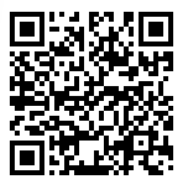